# Task 1: Face Recognition with Embedding Comparison

**Goal:** Train **Method 5** (ViT-B/16 + ArcFace) and compare it against\
pretrained checkpoints from Methods 1–3.

| Method | Backbone | Loss |
|--------|----------|------|
| 1 | Custom CNN | Softmax + CrossEntropy |
| 2 | Custom CNN | Triplet Loss |
| 3 | Custom CNN | ArcFace |
| 5 | **ViT-B/16 (pretrained)** | **ArcFace** |

**Evaluation:** ROC Curve + AUC on `verification_pairs_val.txt`\
using Cosine & Euclidean distance across all available checkpoints.

```
dataset/
├── classification_data/
│   ├── train_data/   # 4000 identities
│   ├── val_data/     # 4000 identities
│   └── test_data/
├── verification_data/       # flat folder of images
├── verification_pairs_val.txt
└── verification_pairs_test.txt
```

## Section 0 – Setup & Imports

In [1]:
mkdir -p ~/.kaggle && echo KGAT_481a09343ecc7630e831143a9136dd78 > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [2]:
import sys
!{sys.executable} -m pip install kagglehub torch torchvision timm scikit-learn matplotlib seaborn tqdm Pillow numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 68.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 67.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 68.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 74.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 52.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 70.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 74.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22/22 [timm]2m21/22 [timm]esdk]rn]


In [3]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('11-785-fall-20-homework-2-part-2')

print("Path to competition files:", path)

100%|██████████| 1.35G/1.35G [00:49<00:00, 29.2MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/11-785-fall-20-homework-2-part-2


In [4]:
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import csv

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm

from sklearn.metrics import roc_curve, auc, accuracy_score

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# --- Device ---
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
print(f'Using device: {DEVICE}')

# --- Paths ---
PROJECT_ROOT = Path('.')
DATA_ROOT    = PROJECT_ROOT / '/root/.cache/kagglehub/competitions/11-785-fall-20-homework-2-part-2'

TRAIN_DIR  = DATA_ROOT / 'classification_data' / 'train_data'
VAL_DIR    = DATA_ROOT / 'classification_data' / 'val_data'
TEST_DIR   = DATA_ROOT / 'classification_data' / 'test_data'
VERIF_DIR  = DATA_ROOT / 'verification_data'
VAL_PAIRS  = DATA_ROOT / 'verification_pairs_val.txt'
TEST_PAIRS = DATA_ROOT / 'verification_pairs_test.txt'
SAMPLE_SUB = DATA_ROOT / 'hw2p2_sample_submission.csv'

CKPT_DIR   = PROJECT_ROOT / 'checkpoints'
EMBED_DIR  = PROJECT_ROOT / 'embeddings'
RESULT_DIR = PROJECT_ROOT / 'results'

for d in [CKPT_DIR, EMBED_DIR, RESULT_DIR]:
    d.mkdir(exist_ok=True)

# --- Shared hyperparameters ---
IMG_SIZE       = 112     # CNN models
IMG_SIZE_VIT   = 224     # ViT requires 224x224
EMBED_DIM      = 512
BATCH_SIZE     = 32
NUM_WORKERS    = 8
EPOCHS         = 35

# --- Method 5: ViT-B/16 + ArcFace ---
LR_M5          = 5e-5    # smaller lr for pretrained backbone
ARCFACE_S_M5   = 32.0
ARCFACE_M_M5   = 0.35
WD_M5          = 5e-4

print('Setup complete.')

Using device: cuda
Setup complete.


## Section 1 – Data Exploration (EDA)

In [5]:
def count_dataset(root):
    identities = sorted([d for d in root.iterdir() if d.is_dir()])
    imgs_per_id = [len(list(d.glob('*.jpg')) + list(d.glob('*.png'))) for d in identities]
    return identities, imgs_per_id

train_ids, train_counts = count_dataset(TRAIN_DIR)
val_ids,   val_counts   = count_dataset(VAL_DIR)
test_ids,  test_counts  = count_dataset(TEST_DIR)

print(f'Train: {len(train_ids):,} identities | {sum(train_counts):,} images | mean {np.mean(train_counts):.1f}/id')
print(f'Val  : {len(val_ids):,} identities | {sum(val_counts):,} images | mean {np.mean(val_counts):.1f}/id')
print(f'Test : {len(test_ids):,} identities | {sum(test_counts):,} images')

verif_imgs = list(VERIF_DIR.glob('*.jpg'))
print(f'Verification images: {len(verif_imgs):,}')

with open(VAL_PAIRS) as f:
    val_pairs_lines = f.read().splitlines()
same_pairs = sum(1 for l in val_pairs_lines if l.split()[-1] == '1')
diff_pairs = sum(1 for l in val_pairs_lines if l.split()[-1] == '0')
print(f'Val pairs: {len(val_pairs_lines):,} | Same={same_pairs:,} | Diff={diff_pairs:,}')

Train: 4,000 identities | 380,638 images | mean 95.2/id
Val  : 4,000 identities | 8,000 images | mean 2.0/id
Test : 4,000 identities | 8,000 images
Verification images: 69,097
Val pairs: 8,805 | Same=4,315 | Diff=4,490


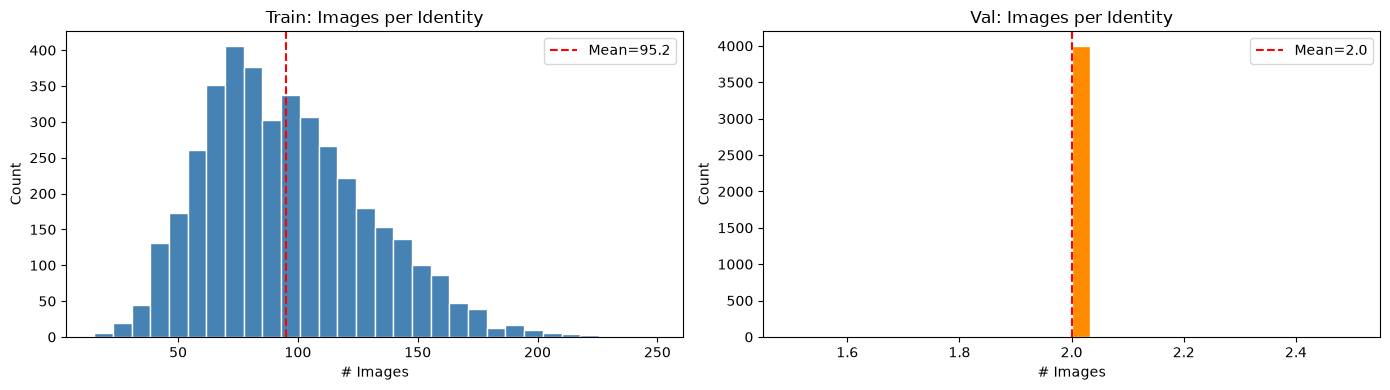

In [6]:
# Distribution of images per identity
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(train_counts, bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Train: Images per Identity')
axes[0].set_xlabel('# Images'); axes[0].set_ylabel('Count')
axes[0].axvline(np.mean(train_counts), color='red', linestyle='--',
                label=f'Mean={np.mean(train_counts):.1f}')
axes[0].legend()

axes[1].hist(val_counts, bins=30, color='darkorange', edgecolor='white')
axes[1].set_title('Val: Images per Identity')
axes[1].set_xlabel('# Images'); axes[1].set_ylabel('Count')
axes[1].axvline(np.mean(val_counts), color='red', linestyle='--',
                label=f'Mean={np.mean(val_counts):.1f}')
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULT_DIR / 'dataset_distribution.png', dpi=120)
plt.show()

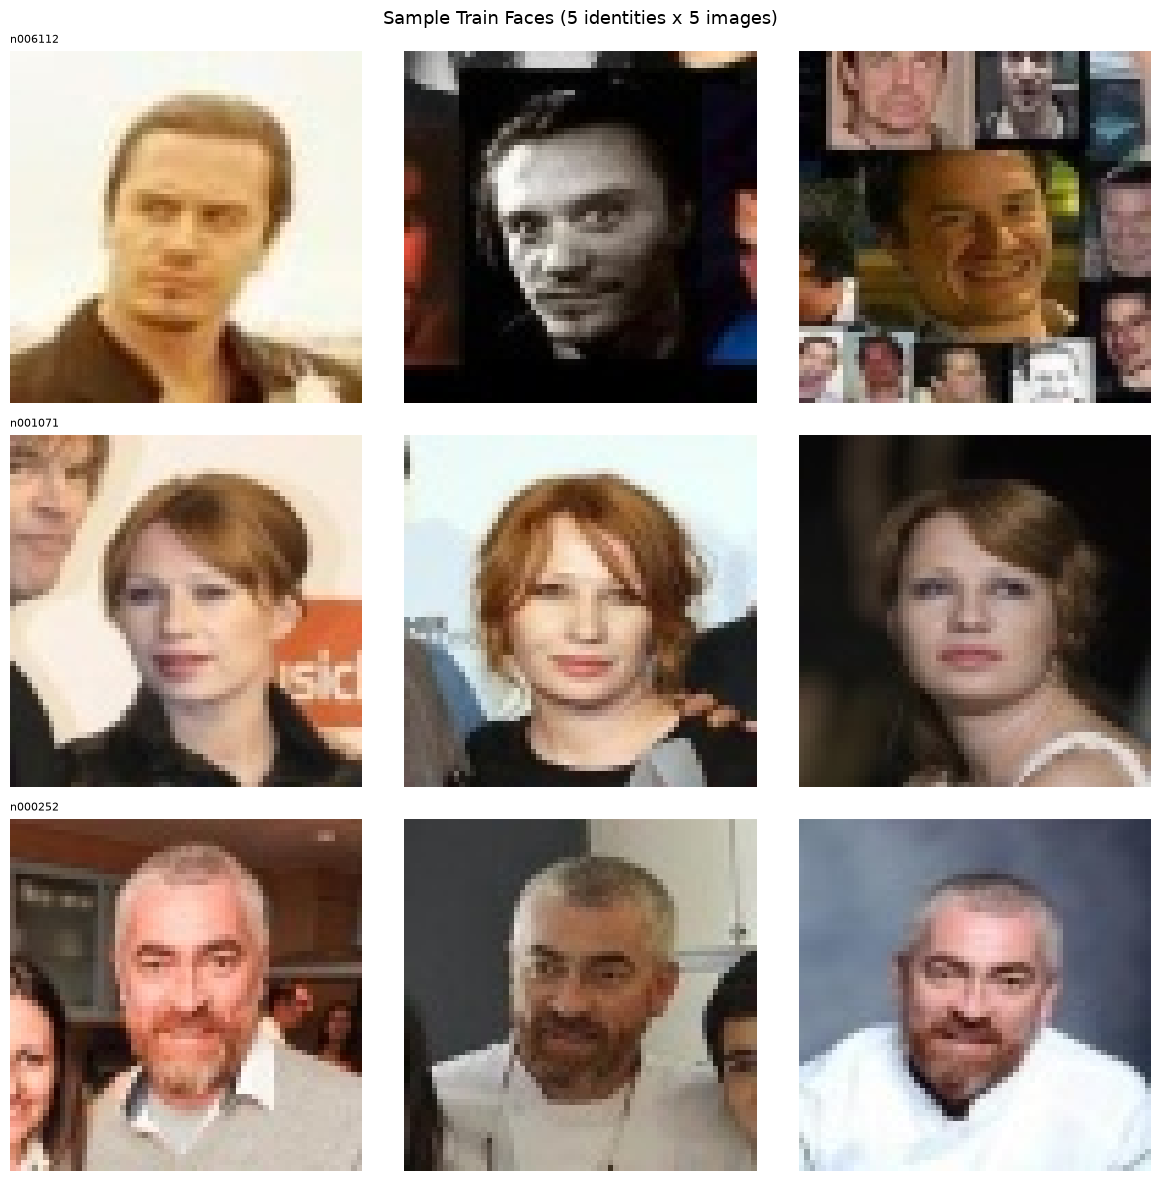

In [7]:
# Sample images grid (5 identities x 5 images)
sample_ids = random.sample(train_ids, 3)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, identity in enumerate(sample_ids):
    imgs = sorted(identity.glob('*.jpg'))[:3]
    for col, img_path in enumerate(imgs):
        ax = axes[row][col]
        img = Image.open(img_path).convert('RGB')
        ax.imshow(img)
        ax.axis('off')
        if col == 0:
            ax.set_title(identity.name, fontsize=8, loc='left')

plt.suptitle('Sample Train Faces (5 identities x 5 images)', fontsize=13)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'sample_faces.png', dpi=120)
plt.show()

## Section 2 – Datasets & DataLoaders

In [8]:
MEAN = [0.5, 0.5, 0.5]
STD  = [0.5, 0.5, 0.5]

# ── CNN transforms (112×112) – kept for loading old checkpoints ──────────────
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomCrop(IMG_SIZE, padding=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# ── ViT transforms (224×224) – for Method 5 ─────────────────────────────────
MEAN_VIT = [0.485, 0.456, 0.406]   # ImageNet stats (ViT pretrained on ImageNet)
STD_VIT  = [0.229, 0.224, 0.225]

train_transform_vit = transforms.Compose([
    transforms.Resize((IMG_SIZE_VIT, IMG_SIZE_VIT)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN_VIT, STD_VIT),
])

val_transform_vit = transforms.Compose([
    transforms.Resize((IMG_SIZE_VIT, IMG_SIZE_VIT)),
    transforms.CenterCrop(IMG_SIZE_VIT),
    transforms.ToTensor(),
    transforms.Normalize(MEAN_VIT, STD_VIT),
])

In [9]:
# ---------- FaceClassificationDataset ----------
class FaceClassificationDataset(Dataset):
    """Standard folder dataset: returns (image_tensor, label_int)."""
    def __init__(self, root, transform=None):
        self.transform = transform
        self.samples   = []
        identity_dirs  = sorted([d for d in root.iterdir() if d.is_dir()])
        self.label_to_idx = {d.name: i for i, d in enumerate(identity_dirs)}
        self.num_classes  = len(identity_dirs)
        for id_dir in identity_dirs:
            label = self.label_to_idx[id_dir.name]
            for ext in ('*.jpg', '*.png'):
                for img_path in id_dir.glob(ext):
                    self.samples.append((img_path, label))
        print(f'  {root.name}: {len(self.samples):,} images, {self.num_classes:,} classes')

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform: img = self.transform(img)
        return img, label


# ---------- TripletFaceDataset ----------
class TripletFaceDataset(Dataset):
    """Returns (anchor, positive, negative) with random mining."""
    def __init__(self, root, transform=None):
        self.transform    = transform
        self.label_to_imgs = defaultdict(list)
        identity_dirs = sorted([d for d in root.iterdir() if d.is_dir()])
        for i, id_dir in enumerate(identity_dirs):
            imgs = list(id_dir.glob('*.jpg')) + list(id_dir.glob('*.png'))
            if len(imgs) >= 2:
                self.label_to_imgs[i] = imgs
        self.all_labels = list(self.label_to_imgs.keys())
        self.samples = [(img, lbl)
                        for lbl, imgs in self.label_to_imgs.items()
                        for img in imgs]
        print(f'  Triplet {root.name}: {len(self.samples):,} images, '
              f'{len(self.all_labels):,} usable identities')

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        anchor_path, anchor_lbl = self.samples[idx]
        # Positive
        pos_candidates = [p for p in self.label_to_imgs[anchor_lbl] if p != anchor_path]
        pos_path = random.choice(pos_candidates)
        # Negative
        neg_lbl  = random.choice([l for l in self.all_labels if l != anchor_lbl])
        neg_path = random.choice(self.label_to_imgs[neg_lbl])

        def load(p):
            img = Image.open(p).convert('RGB')
            return self.transform(img) if self.transform else img

        return load(anchor_path), load(pos_path), load(neg_path)


# ---------- VerificationDataset ----------
class VerificationDataset(Dataset):
    """Reads pairs_file, returns (img1, img2, label)."""
    def __init__(self, pairs_file, transform=None, has_labels=True):
        self.transform  = transform
        self.has_labels = has_labels
        self.pairs      = []
        base_dir = pairs_file.parent
        with open(pairs_file) as f:
            for line in f:
                parts = line.strip().split()
                if has_labels and len(parts) == 3:
                    self.pairs.append((base_dir/parts[0], base_dir/parts[1], int(parts[2])))
                elif not has_labels and len(parts) >= 2:
                    self.pairs.append((base_dir/parts[0], base_dir/parts[1], f'{parts[0]} {parts[1]}'))
        print(f'  {pairs_file.name}: {len(self.pairs):,} pairs')

    def __len__(self):  return len(self.pairs)

    def __getitem__(self, idx):
        p1, p2, meta = self.pairs[idx]
        def load(p):
            img = Image.open(p).convert('RGB')
            return self.transform(img) if self.transform else img
        return load(p1), load(p2), meta

In [10]:
print('=== Building Datasets ===')
clf_train_ds = FaceClassificationDataset(TRAIN_DIR, transform=train_transform)
clf_val_ds   = FaceClassificationDataset(VAL_DIR,   transform=val_transform)
NUM_CLASSES  = clf_train_ds.num_classes

# ViT datasets (224×224)
clf_train_vit_ds = FaceClassificationDataset(TRAIN_DIR, transform=train_transform_vit)
clf_val_vit_ds   = FaceClassificationDataset(VAL_DIR,   transform=val_transform_vit)

verif_val_ds  = VerificationDataset(VAL_PAIRS,  transform=val_transform, has_labels=True)
verif_test_ds = VerificationDataset(TEST_PAIRS, transform=val_transform, has_labels=False)

# ViT verification loaders (224×224)
verif_val_vit_ds  = VerificationDataset(VAL_PAIRS,  transform=val_transform_vit, has_labels=True)
verif_test_vit_ds = VerificationDataset(TEST_PAIRS, transform=val_transform_vit, has_labels=False)

# DataLoaders
clf_train_loader = DataLoader(clf_train_ds,  batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True)
clf_val_loader   = DataLoader(clf_val_ds,    batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)

clf_train_vit_loader = DataLoader(clf_train_vit_ds, batch_size=BATCH_SIZE, shuffle=True,
                                  num_workers=NUM_WORKERS, pin_memory=True)
clf_val_vit_loader   = DataLoader(clf_val_vit_ds,   batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

verif_val_loader     = DataLoader(verif_val_ds,      batch_size=128, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)
verif_test_loader    = DataLoader(verif_test_ds,     batch_size=128, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

verif_val_vit_loader  = DataLoader(verif_val_vit_ds,  batch_size=64, shuffle=False,
                                   num_workers=NUM_WORKERS, pin_memory=True)
verif_test_vit_loader = DataLoader(verif_test_vit_ds, batch_size=64, shuffle=False,
                                   num_workers=NUM_WORKERS, pin_memory=True)

print('\nAll DataLoaders ready.')

=== Building Datasets ===
  train_data: 380,638 images, 4,000 classes
  val_data: 8,000 images, 4,000 classes
  train_data: 380,638 images, 4,000 classes
  val_data: 8,000 images, 4,000 classes
  verification_pairs_val.txt: 8,805 pairs
  verification_pairs_test.txt: 51,835 pairs
  verification_pairs_val.txt: 8,805 pairs
  verification_pairs_test.txt: 51,835 pairs

All DataLoaders ready.


## Section 3 – Legacy CNN Architectures (for loading existing checkpoints)

These classes are kept so that Method 1–3 checkpoints can be loaded in the evaluation section.
**No training is performed here.**

In [16]:
# --- Building Blocks ---
class ConvBlock(nn.Module):
    """Conv3x3 -> BN -> ReLU -> optional MaxPool2d(2)"""
    def __init__(self, in_ch, out_ch, pool=False):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if pool: layers.append(nn.MaxPool2d(2))
        self.block = nn.Sequential(*layers)

    def forward(self, x): return self.block(x)


class ResBlock(nn.Module):
    """Lightweight residual block (same spatial size in/out)."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch),
        )

    def forward(self, x): return F.relu(self.net(x) + x, inplace=True)


# --- Backbone ---
class FaceCNN(nn.Module):
    """
    Custom CNN backbone.
    Input : (B, 3, 112, 112)
    Output: (B, embed_dim) – L2-normalized

    Spatial flow:  112 -> 56 -> 28 -> 14 -> 7 -> 3 -> 1
    Channels:        3    32    64   128   256   512
    """
    def __init__(self, embed_dim=512):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32,  pool=True),   # 112->56
            ConvBlock(32,  64,  pool=True),   # 56->28
            ResBlock(64),
            ConvBlock(64,  128, pool=True),   # 28->14
            ResBlock(128),
            ConvBlock(128, 256, pool=True),   # 14->7
            ResBlock(256),
            ConvBlock(256, 512, pool=True),   # 7->3
            nn.AdaptiveAvgPool2d(1),          # 3->1
        )
        self.emb_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, embed_dim),
            nn.BatchNorm1d(embed_dim),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.emb_head(x)
        return F.normalize(x, p=2, dim=1)   # L2-normalize


# --- Method 1: Classification model ---
class FaceCNN_Classifier(nn.Module):
    def __init__(self, num_classes, embed_dim=512):
        super().__init__()
        self.backbone   = FaceCNN(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        emb    = self.backbone(x)
        logits = self.classifier(emb)
        return logits, emb

    def get_embedding(self, x): return self.backbone(x)


# --- Method 2: Triplet model ---
class FaceCNN_Triplet(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)

    def forward(self, a, p, n):
        return self.backbone(a), self.backbone(p), self.backbone(n)

    def get_embedding(self, x): return self.backbone(x)


# --- ArcFace margin head ---
class ArcFaceHead(nn.Module):
    """
    ArcFace (Additive Angular Margin) classification head.
    Reference: Deng et al. (2019).
    """
    def __init__(self, embed_dim: int, num_classes: int,
                 s: float = 64.0, m: float = 0.5):
        super().__init__()
        self.s = s
        self.m = m
        self.weight = nn.Parameter(torch.empty(num_classes, embed_dim))
        nn.init.xavier_uniform_(self.weight)
        import math
        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th    = math.cos(math.pi - m)
        self.mm    = math.sin(math.pi - m) * m

    def forward(self, embeddings, labels=None):
        w_norm    = F.normalize(self.weight, p=2, dim=1)
        cos_theta = F.linear(embeddings, w_norm).clamp(-1 + 1e-7, 1 - 1e-7)
        if labels is None:
            return self.s * cos_theta
        sin_theta   = torch.sqrt(1.0 - cos_theta ** 2)
        cos_theta_m = cos_theta * self.cos_m - sin_theta * self.sin_m
        cos_theta_m = torch.where(cos_theta > self.th, cos_theta_m,
                                  cos_theta - self.mm)
        one_hot = torch.zeros_like(cos_theta)
        one_hot.scatter_(1, labels.view(-1, 1).long(), 1.0)
        return (one_hot * cos_theta_m + (1.0 - one_hot) * cos_theta) * self.s


# --- Method 3: ArcFace model (CNN backbone + ArcFace head) ---
class FaceCNN_ArcFace(nn.Module):
    """Same FaceCNN backbone + ArcFace margin head."""
    def __init__(self, num_classes: int, embed_dim: int = 512,
                 s: float = 64.0, m: float = 0.5):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)
        self.head     = ArcFaceHead(embed_dim, num_classes, s=s, m=m)

    def forward(self, x, labels=None):
        emb    = self.backbone(x)
        logits = self.head(emb, labels)
        return logits, emb

    def get_embedding(self, x):
        return self.backbone(x)


print('CNN + ArcFace architecture classes defined (for checkpoint loading).')

CNN + ArcFace architecture classes defined (for checkpoint loading).


## Section 4 – Method 5: ViT-B/16 + ArcFace

**ViT-B/16** (Vision Transformer, pretrained on ImageNet-21k via `timm`) is used as the backbone.
The classification head is replaced with an **ArcFace** margin head for metric learning.

Why ViT-B/16 + ArcFace?
- ViT captures global facial structure via self-attention (no inductive CNN bias).
- ArcFace is SOTA for face recognition: enforces angular margin in hyperspherical space.
- Pretrained weights give a strong initialization → faster convergence, better AUC.

In [12]:
class FaceViT_ArcFace(nn.Module):
    """
    Method 5: ViT-B/16 pretrained backbone + ArcFace margin head.

    Input : (B, 3, 224, 224)  – ImageNet normalization
    Output: logits (B, num_classes) during training,
            embedding (B, embed_dim) L2-normalized via get_embedding()
    """
    def __init__(self, num_classes: int, embed_dim: int = 512,
                 s: float = 32.0, m: float = 0.35):
        super().__init__()

        # --- Backbone: ViT-B/16 pretrained, no classifier head ---
        self.backbone = timm.create_model(
            'vit_base_patch16_224',
            pretrained=True,
            num_classes=0,        # remove default head → outputs (B, 768)
        )
        vit_dim = self.backbone.num_features  # 768

        # --- Projection head: ViT dim → embed_dim, then BN ---
        self.emb_head = nn.Sequential(
            nn.Linear(vit_dim, embed_dim, bias=False),
            nn.BatchNorm1d(embed_dim),
        )

        # --- ArcFace weight matrix ---
        self.weight = nn.Parameter(torch.empty(num_classes, embed_dim))
        nn.init.xavier_uniform_(self.weight)

        self.s     = s
        self.m     = m
        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th    = math.cos(math.pi - m)   # cos(π − m)
        self.mm    = math.sin(math.pi - m) * m

    # -----------------------------------------------------------------
    def _arc_logits(self, emb, labels):
        """Compute ArcFace logits given L2-normed embeddings."""
        cosine = F.linear(emb, F.normalize(self.weight, p=2, dim=1))
        sine   = torch.sqrt((1.0 - cosine ** 2).clamp(1e-7, 1.0))
        phi    = cosine * self.cos_m - sine * self.sin_m          # cos(θ + m)
        phi    = torch.where(cosine > self.th, phi, cosine - self.mm)
        one_hot = torch.zeros_like(cosine)
        one_hot.scatter_(1, labels.view(-1, 1).long(), 1.0)
        return (one_hot * phi + (1.0 - one_hot) * cosine) * self.s

    # -----------------------------------------------------------------
    def forward(self, x, labels=None):
        feat = self.backbone(x)                          # (B, 768)
        emb  = self.emb_head(feat)                       # (B, embed_dim)
        emb  = F.normalize(emb, p=2, dim=1)

        if labels is None:    # inference / eval
            logits = F.linear(emb, F.normalize(self.weight, p=2, dim=1)) * self.s
        else:                 # training
            logits = self._arc_logits(emb, labels)
        return logits, emb

    def get_embedding(self, x):
        feat = self.backbone(x)
        emb  = self.emb_head(feat)
        return F.normalize(emb, p=2, dim=1)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    print(f'  Total params: {total:,}')

print('=== FaceViT_ArcFace ===')
_m5 = FaceViT_ArcFace(100, EMBED_DIM)   # dummy num_classes for shape check
count_params(_m5)
_x  = torch.randn(2, 3, IMG_SIZE_VIT, IMG_SIZE_VIT)
_lb = torch.randint(0, 100, (2,))
_lg, _em = _m5(_x, _lb)
print(f'  logits: {_lg.shape} | embedding: {_em.shape}')
del _m5, _x, _lb, _lg, _em

=== FaceViT_ArcFace ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

  Total params: 86,244,096
  logits: torch.Size([2, 100]) | embedding: torch.Size([2, 512])


In [13]:
# ── Method 5: ViT-B/16 + ArcFace – Training ────────────────────────────────
def train_vit_arcface(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc='  Train', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits, _ = model(imgs, labels)        # ArcFace logits
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            logits_clean, _ = model(imgs, None)  # plain cosine logits for acc
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits_clean.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def eval_vit_arcface(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc='  Val  ', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        logits, _ = model(imgs, labels)
        loss = criterion(logits, labels)
        logits_clean, _ = model(imgs, None)
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits_clean.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


# --- Instantiate ---
model5     = FaceViT_ArcFace(NUM_CLASSES, EMBED_DIM, s=ARCFACE_S_M5, m=ARCFACE_M_M5).to(DEVICE)
criterion5 = nn.CrossEntropyLoss()
optimizer5 = torch.optim.AdamW(model5.parameters(), lr=LR_M5, weight_decay=WD_M5)
scheduler5 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer5, T_max=EPOCHS)

history5 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss5 = float('inf')

print(f'Training Method 5 (ViT-B/16 + ArcFace) for {EPOCHS} epochs on {DEVICE}...')
print(f'  s={ARCFACE_S_M5}, m={ARCFACE_M_M5}, lr={LR_M5}')
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_vit_arcface(model5, clf_train_vit_loader, criterion5, optimizer5, DEVICE)
    va_loss, va_acc = eval_vit_arcface(model5, clf_val_vit_loader,   criterion5, DEVICE)
    scheduler5.step()
    history5['train_loss'].append(tr_loss); history5['train_acc'].append(tr_acc)
    history5['val_loss'].append(va_loss);   history5['val_acc'].append(va_acc)
    if va_loss < best_val_loss5:
        best_val_loss5 = va_loss
        torch.save(model5.state_dict(), CKPT_DIR / 'method5_best.pth')
        marker = ' <- BEST'
    else:
        marker = ''
    print(f'Ep {epoch:02d}/{EPOCHS} | TrLoss {tr_loss:.4f} TrAcc {tr_acc*100:.1f}% '
          f'| VaLoss {va_loss:.4f} VaAcc {va_acc*100:.1f}%{marker}')

print(f'\nBest Val Loss (M5): {best_val_loss5:.4f}')

Training Method 5 (ViT-B/16 + ArcFace) for 35 epochs on cuda...
  s=32.0, m=0.35, lr=5e-05


Ep 01/35 | TrLoss 16.2130 TrAcc 22.3% | VaLoss 12.5209 VaAcc 48.7% <- BEST


Ep 02/35 | TrLoss 9.1443 TrAcc 76.2% | VaLoss 7.5279 VaAcc 75.4% <- BEST


Ep 03/35 | TrLoss 5.3902 TrAcc 89.9% | VaLoss 5.4530 VaAcc 82.9% <- BEST


Ep 04/35 | TrLoss 3.6188 TrAcc 94.3% | VaLoss 4.4943 VaAcc 85.3% <- BEST


Ep 05/35 | TrLoss 2.6100 TrAcc 96.3% | VaLoss 4.0713 VaAcc 86.0% <- BEST


... (26 outputs left out)

Ep 32/35 | TrLoss 0.0065 TrAcc 100.0% | VaLoss 2.3193 VaAcc 90.5% <- BEST


Ep 33/35 | TrLoss 0.0052 TrAcc 100.0% | VaLoss 2.3035 VaAcc 90.6% <- BEST


Ep 34/35 | TrLoss 0.0042 TrAcc 100.0% | VaLoss 2.2825 VaAcc 90.6% <- BEST


Ep 35/35 | TrLoss 0.0045 TrAcc 100.0% | VaLoss 2.2784 VaAcc 90.7% <- BEST

Best Val Loss (M5): 2.2784


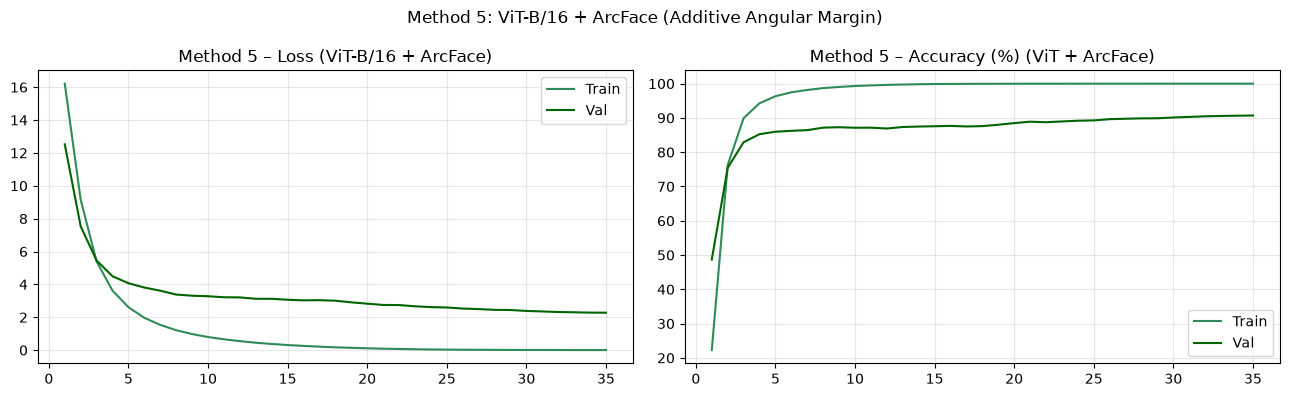

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep = range(1, EPOCHS + 1)
axes[0].plot(ep, history5['train_loss'], label='Train', color='seagreen')
axes[0].plot(ep, history5['val_loss'],   label='Val',   color='darkgreen')
axes[0].set_title('Method 5 – Loss (ViT-B/16 + ArcFace)'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, [a*100 for a in history5['train_acc']], label='Train', color='seagreen')
axes[1].plot(ep, [a*100 for a in history5['val_acc']],   label='Val',   color='darkgreen')
axes[1].set_title('Method 5 – Accuracy (%) (ViT + ArcFace)'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.suptitle('Method 5: ViT-B/16 + ArcFace (Additive Angular Margin)', fontsize=12)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'method5_curves.png', dpi=120)
plt.show()

## Section 5 – Evaluation: ROC Curve & AUC

In [17]:
# ─────────────────────────────────────────────────────────────────────────────
# Load checkpoints for all 5 methods.
# Each model is added to AVAILABLE_MODELS only if its checkpoint exists.
# ─────────────────────────────────────────────────────────────────────────────
AVAILABLE_MODELS = {}   # name -> (model, verif_loader)

def try_load(name, model_cls, ckpt_name, loader, *args, **kwargs):
    ckpt = CKPT_DIR / ckpt_name
    if not ckpt.exists():
        print(f'[SKIP] {name}: checkpoint not found ({ckpt})')
        return
    m = model_cls(*args, **kwargs).to(DEVICE)
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    m.eval()
    AVAILABLE_MODELS[name] = (m, loader)
    print(f'[OK]   {name}: loaded from {ckpt_name}')

try_load('Method1', FaceCNN_Classifier, 'method1_best.pth', verif_val_loader,
         NUM_CLASSES, EMBED_DIM)
try_load('Method2', FaceCNN_Triplet,    'method2_best.pth', verif_val_loader,
         EMBED_DIM)
try_load('Method3', FaceCNN_ArcFace,    'method3_best.pth', verif_val_loader,
         NUM_CLASSES, EMBED_DIM)
try_load('Method4', FaceCNN_Triplet,    'method4_best.pth', verif_val_loader,
         EMBED_DIM)
try_load('Method5', FaceViT_ArcFace,    'method5_best.pth', verif_val_vit_loader,
         NUM_CLASSES, EMBED_DIM)

print(f'\nAvailable models: {list(AVAILABLE_MODELS.keys())}')

[OK]   Method1: loaded from method1_best.pth
[OK]   Method2: loaded from method2_best.pth
[OK]   Method3: loaded from method3_best.pth
[OK]   Method4: loaded from method4_best.pth
[OK]   Method5: loaded from method5_best.pth

Available models: ['Method1', 'Method2', 'Method3', 'Method4', 'Method5']


In [18]:
@torch.no_grad()
def extract_pair_embeddings(model, loader, device):
    """Returns emb1 (N,D), emb2 (N,D), labels (N,)."""
    model.eval()
    e1s, e2s, lbls = [], [], []
    for img1, img2, label in tqdm(loader, desc='  Extracting'):
        e1s.append(model.get_embedding(img1.to(device)).cpu().numpy())
        e2s.append(model.get_embedding(img2.to(device)).cpu().numpy())
        lbls.append(np.array(label))
    return np.concatenate(e1s), np.concatenate(e2s), np.concatenate(lbls)


# Extract & cache embeddings for all available models
emb_data = {}   # name -> (emb1, emb2, labels)
for name, (model, loader) in AVAILABLE_MODELS.items():
    print(f'Extracting {name} embeddings...')
    e1, e2, lbl = extract_pair_embeddings(model, loader, DEVICE)
    emb_data[name] = (e1, e2, lbl)
    np.savez(EMBED_DIR / f'{name.lower()}_val.npz', emb1=e1, emb2=e2, labels=lbl)

print('Done.')

Extracting Method1 embeddings...


  Extracting:   0%|          | 0/69 [00:00<?, ?it/s]/tmp/ipykernel_1160/1662851600.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  lbls.append(np.array(label))
  Extracting: 100%|██████████| 69/69 [00:02<00:00, 34.43it/s]


Extracting Method2 embeddings...


  Extracting: 100%|██████████| 69/69 [00:01<00:00, 41.47it/s]


Extracting Method3 embeddings...


  Extracting: 100%|██████████| 69/69 [00:01<00:00, 40.72it/s]


Extracting Method4 embeddings...


  Extracting: 100%|██████████| 69/69 [00:01<00:00, 39.50it/s]


Extracting Method5 embeddings...


  Extracting: 100%|██████████| 138/138 [00:17<00:00,  8.09it/s]


Done.


In [19]:
def cosine_sim(e1, e2):     return np.sum(e1 * e2, axis=1)
def euclidean_dist(e1, e2): return np.sqrt(np.sum((e1 - e2) ** 2, axis=1))


def compute_roc_metrics(scores, labels):
    """scores: higher => same person."""
    fpr, tpr, thrs = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)
    fnr     = 1 - tpr
    idx_eer = np.nanargmin(np.abs(fnr - fpr))
    eer     = (fpr[idx_eer] + fnr[idx_eer]) / 2
    j        = tpr - fpr
    best_thr = thrs[np.argmax(j)]
    best_acc = accuracy_score(labels, (scores >= best_thr).astype(int))
    return fpr, tpr, roc_auc, eer, best_thr, best_acc


# Build settings dict dynamically from available models
settings = {}
for name, (e1, e2, lbl) in emb_data.items():
    settings[f'{name} + Cosine']    = (cosine_sim(e1, e2),       lbl)
    settings[f'{name} + Euclidean'] = (-euclidean_dist(e1, e2),  lbl)

results = {}
for name, (scores, labels) in settings.items():
    fpr, tpr, rac, eer, thr, acc = compute_roc_metrics(scores, labels)
    results[name] = dict(fpr=fpr, tpr=tpr, auc=rac, eer=eer, thresh=thr, acc=acc)
    print(f'{name:35s}  AUC={rac:.4f}  EER={eer*100:.2f}%  BestAcc={acc*100:.2f}%')

Method1 + Cosine                     AUC=0.9330  EER=12.94%  BestAcc=87.36%
Method1 + Euclidean                  AUC=0.9330  EER=12.94%  BestAcc=87.36%
Method2 + Cosine                     AUC=0.9064  EER=17.40%  BestAcc=83.03%
Method2 + Euclidean                  AUC=0.9064  EER=17.40%  BestAcc=83.03%
Method3 + Cosine                     AUC=0.9400  EER=12.78%  BestAcc=87.29%
Method3 + Euclidean                  AUC=0.9400  EER=12.78%  BestAcc=87.29%
Method4 + Cosine                     AUC=0.8871  EER=18.94%  BestAcc=81.89%
Method4 + Euclidean                  AUC=0.8871  EER=18.94%  BestAcc=81.89%
Method5 + Cosine                     AUC=0.9078  EER=16.88%  BestAcc=84.11%
Method5 + Euclidean                  AUC=0.9078  EER=16.88%  BestAcc=84.11%


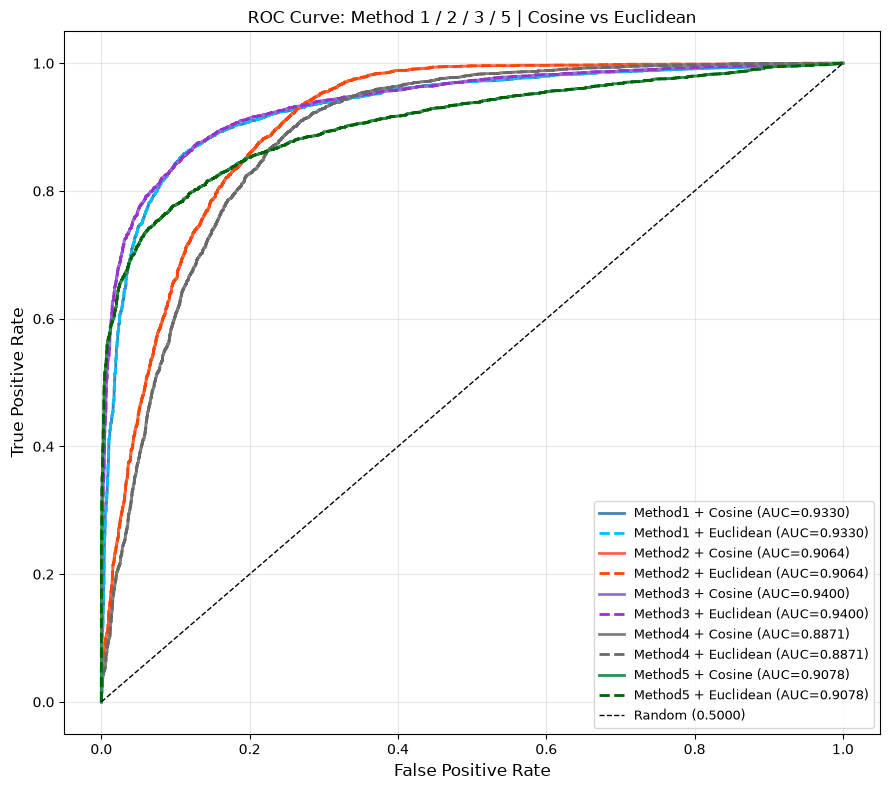

In [20]:
# ── ROC Curves (all available models) ────────────────────────────────────────
PALETTE = [
    ('steelblue',    'deepskyblue'),   # Method1
    ('tomato',       'orangered'),     # Method2
    ('mediumpurple', 'darkorchid'),    # Method3
    ('seagreen',     'darkgreen'),     # Method5
]
# Map model name -> color pair
model_names_ordered = ['Method1', 'Method2', 'Method3', 'Method5']
color_map = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(model_names_ordered)}

plt.figure(figsize=(9, 8))
for setting_name, res in results.items():
    model_key = setting_name.split(' + ')[0]
    c_solid, c_dash = color_map.get(model_key, ('gray', 'dimgray'))
    ls = '-' if 'Cosine' in setting_name else '--'
    color = c_solid if 'Cosine' in setting_name else c_dash
    plt.plot(res['fpr'], res['tpr'], color=color, linestyle=ls, lw=2,
             label=f"{setting_name} (AUC={res['auc']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (0.5000)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve: Method 1 / 2 / 3 / 5 | Cosine vs Euclidean', fontsize=12)
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'roc_curves.png', dpi=150)
plt.show()

In [21]:
# Summary table
print('=' * 80)
print(f'{"Method":<35} {"AUC":>8} {"EER":>8} {"Best Acc":>10} {"Threshold":>11}')
print('-' * 80)
for name, res in sorted(results.items(), key=lambda x: -x[1]['auc']):
    print(f'{name:<35} {res["auc"]:>8.4f} {res["eer"]*100:>7.2f}% '
          f'{res["acc"]*100:>9.2f}% {res["thresh"]:>11.4f}')
print('=' * 80)

BEST_CONFIG = max(results, key=lambda k: results[k]['auc'])
print(f'\n>> Best configuration: {BEST_CONFIG}  (AUC={results[BEST_CONFIG]["auc"]:.4f})')

Method                                   AUC      EER   Best Acc   Threshold
--------------------------------------------------------------------------------
Method3 + Euclidean                   0.9400   12.78%     87.29%     -1.2946
Method3 + Cosine                      0.9400   12.78%     87.29%      0.1620
Method1 + Cosine                      0.9330   12.94%     87.36%      0.2094
Method1 + Euclidean                   0.9330   12.94%     87.36%     -1.2575
Method5 + Euclidean                   0.9078   16.88%     84.11%     -1.3408
Method5 + Cosine                      0.9078   16.88%     84.11%      0.1011
Method2 + Euclidean                   0.9064   17.40%     83.03%     -0.9663
Method2 + Cosine                      0.9064   17.40%     83.03%      0.5331
Method4 + Cosine                      0.8871   18.94%     81.89%      0.3498
Method4 + Euclidean                   0.8871   18.94%     81.89%     -1.1403

>> Best configuration: Method3 + Euclidean  (AUC=0.9400)


Computing t-SNE for Method5 (this may take ~1 min)...


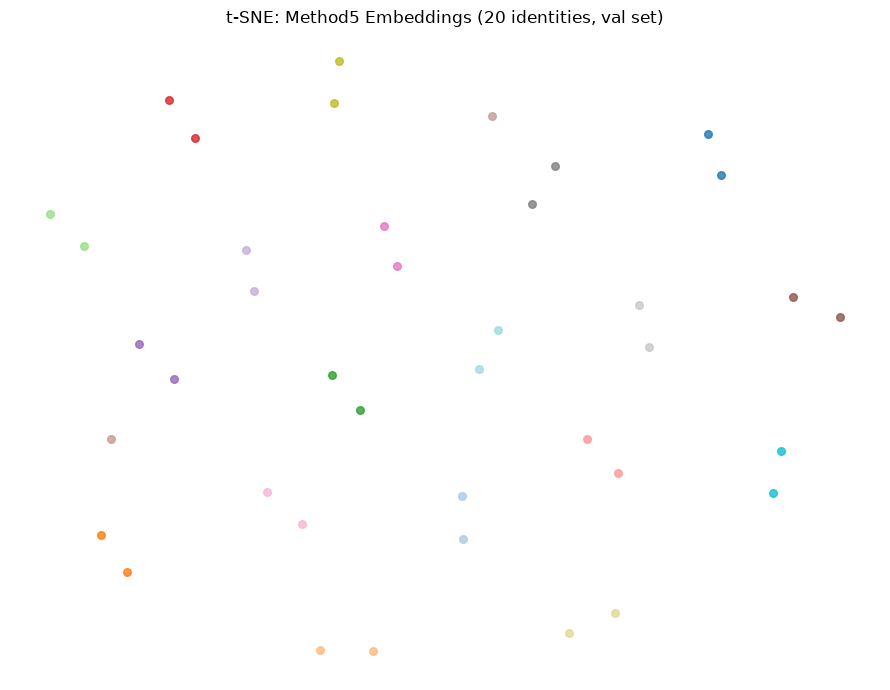

In [22]:
# t-SNE Visualization (20 identities, best available model)
from sklearn.manifold import TSNE

# Pick model to visualize: prefer Method5, else first available
_tsne_name = 'Method5' if 'Method5' in AVAILABLE_MODELS else list(AVAILABLE_MODELS.keys())[0]
_tsne_model, _ = AVAILABLE_MODELS[_tsne_name]
_tsne_loader_transform = val_transform_vit if _tsne_name == 'Method5' else val_transform

@torch.no_grad()
def get_class_embeddings(model, root, n_ids=20, n_per_id=10, transform=None, device='cpu'):
    model.eval()
    id_dirs = random.sample([d for d in root.iterdir() if d.is_dir()], n_ids)
    embs, lbls = [], []
    for lbl, d in enumerate(id_dirs):
        for img_path in list(d.glob('*.jpg'))[:n_per_id]:
            img = Image.open(img_path).convert('RGB')
            if transform: img = transform(img)
            e = model.get_embedding(img.unsqueeze(0).to(device)).cpu().numpy().squeeze()
            embs.append(e); lbls.append(lbl)
    return np.array(embs), np.array(lbls)

print(f'Computing t-SNE for {_tsne_name} (this may take ~1 min)...')
tsne_embs, tsne_lbls = get_class_embeddings(
    _tsne_model, VAL_DIR, n_ids=20, n_per_id=10,
    transform=_tsne_loader_transform, device=DEVICE
)
xy = TSNE(n_components=2, perplexity=15, random_state=SEED).fit_transform(tsne_embs)

plt.figure(figsize=(9, 7))
colors = plt.cm.tab20(np.linspace(0, 1, 20))
for i in range(20):
    m = tsne_lbls == i
    plt.scatter(xy[m, 0], xy[m, 1], color=colors[i], s=30, alpha=0.8, label=f'ID {i}')
plt.title(f't-SNE: {_tsne_name} Embeddings (20 identities, val set)', fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.savefig(RESULT_DIR / f'tsne_{_tsne_name.lower()}.png', dpi=120)
plt.show()

## Section 7 – Test Submission

In [23]:
# ── Select best model & distance for test submission ─────────────────────────
best_model_name = BEST_CONFIG.split(' + ')[0]   # e.g. 'Method5'
best_model, best_verif_loader = AVAILABLE_MODELS[best_model_name]
use_vit_loader = (best_model_name == 'Method5')
verif_test_best = verif_test_vit_loader if use_vit_loader else verif_test_loader

if 'Cosine' in BEST_CONFIG:
    score_fn  = cosine_sim
    threshold = results[BEST_CONFIG]['thresh']
else:
    score_fn  = lambda e1, e2: -euclidean_dist(e1, e2)
    threshold = results[BEST_CONFIG]['thresh']

print(f'Using: {BEST_CONFIG}')
print(f'Threshold: {threshold:.4f}')

@torch.no_grad()
def predict_test(model, loader, score_fn, threshold, device):
    model.eval()
    all_scores, all_meta = [], []
    for img1, img2, meta in tqdm(loader, desc='Test inference'):
        e1 = model.get_embedding(img1.to(device)).cpu().numpy()
        e2 = model.get_embedding(img2.to(device)).cpu().numpy()
        all_scores.extend(score_fn(e1, e2).tolist())
        all_meta.extend(meta)
    scores = np.array(all_scores)
    preds  = (scores >= threshold).astype(int)
    return all_meta, scores, preds

test_meta, test_scores, test_preds = predict_test(
    best_model, verif_test_best, score_fn, threshold, DEVICE
)
print(f'Test pairs: {len(test_preds):,} | Same: {test_preds.sum()} | '
      f'Diff: {(~test_preds.astype(bool)).sum()}')

Using: Method3 + Euclidean
Threshold: -1.2946


Test inference: 100%|██████████| 405/405 [00:07<00:00, 53.23it/s]

Test pairs: 51,835 | Same: 25963 | Diff: 25872


In [24]:
# Write submission.csv
sub_path = RESULT_DIR / 'submission.csv'
with open(sub_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['img1', 'img2', 'label'])
    for pair_str, pred in zip(test_meta, test_preds):
        img1_rel, img2_rel = pair_str.split(' ', 1)
        writer.writerow([img1_rel, img2_rel, int(pred)])

print(f'Submission saved: {sub_path}')

Submission saved: results/submission.csv


## Section 8 – Final Summary

In [25]:
print('='*70)
print('TASK 1 – FACE RECOGNITION: FINAL SUMMARY')
print('='*70)
print(f'Training     : Method 5 (ViT-B/16 + ArcFace)')
print(f'Embedding dim: {EMBED_DIM}  |  ViT input: {IMG_SIZE_VIT}x{IMG_SIZE_VIT}  |  Epochs: {EPOCHS}')
print(f'Models loaded for comparison: {list(AVAILABLE_MODELS.keys())}')
print()
print('VERIFICATION AUC RESULTS (sorted by AUC):')
print('-'*70)
for name, res in sorted(results.items(), key=lambda x: -x[1]['auc']):
    mark = '  <- BEST' if name == BEST_CONFIG else ''
    print(f'  {name:<35}  AUC={res["auc"]:.4f}  EER={res["eer"]*100:.2f}%{mark}')
print('='*70)
print(f'Checkpoints : {CKPT_DIR}')
print(f'Embeddings  : {EMBED_DIR}')
print(f'Results     : {RESULT_DIR}')

TASK 1 – FACE RECOGNITION: FINAL SUMMARY
Training     : Method 5 (ViT-B/16 + ArcFace)
Embedding dim: 512  |  ViT input: 224x224  |  Epochs: 35
Models loaded for comparison: ['Method1', 'Method2', 'Method3', 'Method4', 'Method5']

VERIFICATION AUC RESULTS (sorted by AUC):
----------------------------------------------------------------------
  Method3 + Euclidean                  AUC=0.9400  EER=12.78%  <- BEST
  Method3 + Cosine                     AUC=0.9400  EER=12.78%
  Method1 + Cosine                     AUC=0.9330  EER=12.94%
  Method1 + Euclidean                  AUC=0.9330  EER=12.94%
  Method5 + Euclidean                  AUC=0.9078  EER=16.88%
  Method5 + Cosine                     AUC=0.9078  EER=16.88%
  Method2 + Euclidean                  AUC=0.9064  EER=17.40%
  Method2 + Cosine                     AUC=0.9064  EER=17.40%
  Method4 + Cosine                     AUC=0.8871  EER=18.94%
  Method4 + Euclidean                  AUC=0.8871  EER=18.94%
Checkpoints : checkpoints
Em